BLOK1: YÜKLEME VE İLK BAKIŞ

In [1]:
import pandas as pd #pandas tabloyu yönetir
import numpy as np #eksik değer (np.nan) ve matematiksel işlemler için gereklidir

raw = pd.read_csv("Salary_Data.csv")  #dosyayı dataframe'e atama
df = raw.copy() # ham veri korunur, iş akışı baştan tekrarlanabilir.

print("Boyut (satır , sütun): " , df.shape ) 
df.head()

Boyut (satır , sütun):  (6704, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [2]:
df.info()  #sütunun veri tipini gösterir

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


In [3]:
df.describe(include="all")

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
count,6702.000000,6702,6701,6702,6701.000000,6699.000000
unique,NaN,3,7,193,NaN,NaN
top,NaN,Male,Bachelor's Degree,Software Engineer,NaN,NaN
freq,NaN,3674,2267,518,NaN,NaN
mean,33.620859,NaN,NaN,NaN,8.094687,115326.964771
std,7.614633,NaN,NaN,NaN,6.059003,52786.183911
min,21.000000,NaN,NaN,NaN,0.000000,350.000000
25%,28.000000,NaN,NaN,NaN,3.000000,70000.000000
50%,32.000000,NaN,NaN,NaN,7.000000,115000.000000
75%,38.000000,NaN,NaN,NaN,12.000000,160000.000000


In [4]:
df.nunique()  #her sütundaki farklı değer sayısı

Age                     41
Gender                   3
Education Level          7
Job Title              193
Years of Experience     37
Salary                 444
dtype: int64

BLOK2: EKSİK DEĞERLER

In [5]:
print("Eksik değer sayıları: ")
print(df.isna().sum())   #her sütundaki eksik değer yazılır. isna() eksik hücreler için true üretir, sum() bunları sayar.

Eksik değer sayıları: 
Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64


In [6]:
df[df.isna().any(axis=1)]  #eksik içeren satırların tamamı

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
172,NaN,NaN,NaN,NaN,NaN,NaN
260,NaN,NaN,NaN,NaN,NaN,NaN
2011,27.0,Male,NaN,Developer,7.0,100000.0
3136,31.0,Male,Master's Degree,Full Stack Engineer,8.0,NaN
5247,26.0,Female,Bachelor's Degree,Social M,NaN,NaN
6455,36.0,Male,Bachelor's Degree,Sales Director,6.0,NaN


In [7]:
df = df.dropna(subset = ["Salary"])  #salary'deki eksikleri siler
print(df.isna().sum())

#salary bizim hedefimiz yani test serimiz olacağı için boş hedefler işe yaramaz

Age                    0
Gender                 0
Education Level        1
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64


BLOK3: Etiket Temizliği 

In [8]:
df["Job Title"] = df["Job Title"].str.strip().str.lower()
df["Gender"] = df["Gender"].str.strip().str.lower()
df["Education Level"] = df["Education Level"].str.strip().str.lower()

df["Education Level"] = df["Education Level"].replace(
    {
        "bachelor's degree" : "bachelor's",
        "master's degree" : "master's",
        "phd" : "phd"
    })

print(df["Education Level"].isna().sum())

print(df["Education Level"].value_counts(dropna=False))  #(dropna=False) = eksik değerleri de say ve göster

print(df["Gender"].value_counts(dropna=False)) 


1
Education Level
bachelor's     3021
master's       1860
phd            1369
high school     448
NaN               1
Name: count, dtype: int64
Gender
male      3672
female    3013
other       14
Name: count, dtype: int64


BLOK4: Tekrar Eden Kayıt 

In [9]:
print("Tekrar eden satır sayısı: " , df.duplicated().sum())

Tekrar eden satır sayısı:  4912


In [10]:
tekrar = df[df.duplicated(keep=False)] #ilk kopya dahil tüm tekrarlar
print(tekrar.head(10))
print("Tekrar eden farklı kayıt sayısı: ", tekrar.drop_duplicates().shape[0])

      Age  Gender Education Level                              Job Title  \
140  28.0    male      bachelor's                junior business analyst   
168  31.0  female      bachelor's                  junior hr coordinator   
195  28.0    male      bachelor's                junior business analyst   
209  30.0  female      bachelor's           junior marketing coordinator   
210  38.0    male        master's                   senior it consultant   
211  45.0  female             phd                senior product designer   
212  28.0    male      bachelor's  junior business development associate   
213  35.0  female      bachelor's               senior marketing analyst   
214  44.0    male      bachelor's               senior software engineer   
215  34.0  female        master's               senior financial advisor   

     Years of Experience    Salary  
140                  2.0   40000.0  
168                  4.0   50000.0  
195                  2.0   40000.0  
209            

In [11]:
onceki = df.shape[0]
df = df.drop_duplicates(keep="first").reset_index(drop=True)  #keep="first", aynı satırdan birden fazla varsa ilkini tut, sonrakileri sil demek.
                                                              #reset_index(drop=True), satırların numaralandırmasını (index) baştan, 0'dan başlayarak yeniden sayar.
print("Silinen satır:", onceki - df.shape[0])  #df.shape iki değerden oluşan bir çift verir: (satır sayısı, sütun sayısı) 
                                               #[0] ise bu çiftin ilk elemanını alır, yani sadece satır sayısını
print("Kalan satır:", df.shape[0])
print("Kalan tekrar:", df.duplicated().sum())

print("Salary eksik:", df["Salary"].isna().sum())

Silinen satır: 4912
Kalan satır: 1787
Kalan tekrar: 0
Salary eksik: 0


BLOK5: EDUCATİON LEVEL SAYIYA DÖNÜŞTÜRME

In [12]:
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,male,bachelor's,software engineer,5.0,90000.0
1,28.0,female,master's,data analyst,3.0,65000.0
2,45.0,male,phd,senior manager,15.0,150000.0
3,36.0,female,bachelor's,sales associate,7.0,60000.0
4,52.0,male,master's,director,20.0,200000.0


In [13]:
onceki = df.shape[0]

df["Education Level"] = df["Education Level"].map(
    {"high school" : 0 , "bachelor's" : 1 , "master's" : 2 , "phd" : 3} 
)  #metinsel ifadeleri sıralı sayılara çevirir

df = df.dropna().reset_index(drop=True) #eksik içeren satırları siler
                                        #.reset_index(drop=True): Silmeden sonra oluşan boşlukları kapatır ve index’i 0'dan yeniden sayar.

print("Silinen satır: " , onceki - df.shape[0])
print("Kalan satır: " , df.shape[0])
print("Toplam eksik: " , df.isna().sum().sum())  #df.isna().sum() -> her sütunun tek tek eksik değerlerini verir.
                                                 #ikinci .sum() ise toplam eksik sayısını verir.
print(df["Education Level"].value_counts().sort_index())

Silinen satır:  1
Kalan satır:  1786
Toplam eksik:  0
Education Level
0.0    110
1.0    767
2.0    568
3.0    341
Name: count, dtype: int64


BLOK6: TRAIN/TEST BÖLMESİ
bölmeden sonra test kitlenir
tüm öğrenen işlemler test verisi hesaba katılmadan yapılır
test verisi hesaba katılırsa leakege olur

In [14]:
from sklearn.model_selection import train_test_split
#bölme fonksiyonunu içeri alır

X = df.drop(columns = ["Salary"])
#model için girdi tablosunu oluşturur
#drop ile salary çıkarılır, geriye kalan sütunlar modelin bakıp tahmin yapacağı bilgiler olur
#modelin bir tahminde bulunabilmesi için incelediği tüm özellikler

y = df["Salary"]
#tahmin etmek istediğimiz değer

X_train , X_test , y_train , y_test = train_test_split(
    X , y , test_size=0.20 , random_state=42
)

#X -> girdi sütunları (Age, Gender, Education Level, Job Title ve Years of Experience)
#y -> salary (hedef / target)


BLOK7: AYKIRI DEĞER HESABI

In [15]:
#aykırı değerler yalnızca train sette
#modeli aşırı karmaşadan korumak için aykırı değerleri train setinden ya sileri ya da
#sınır değerine baskılarız clipping
q1 = y_train.quantile(0.25)
q3 = y_train.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

mask = (y_train > lower) & (y_train < upper)  #sınırlar içinde kalanlar

X_train = X_train[mask].copy()
y_train = y_train[mask]

print("Alt sınır:", lower, "| Üst sınır:", upper)
print("Train'den çıkarılan:", (~mask).sum())
print("Yeni train boyutu:", X_train.shape)

#test kümesindeki aykırı değerler silinmez
#silinirse model basitleşir
#gerçek zamanda girdide aykırı değer olabilir

Alt sınır: -58748.375 | Üst sınır: 284580.625
Train'den çıkarılan: 0
Yeni train boyutu: (1428, 5)


BLOK8: Nadir Ünvanları Birleştir

In [16]:
#overfitting'i önlemek için

counts = X_train["Job Title"].value_counts()   # sadece train'deki sayım
#frekans istatistiği

rare = list(counts[counts < 5].index)          # 5'ten az geçen unvanlar

X_train["Job Title"] = X_train["Job Title"].replace(rare, "other")
X_test["Job Title"] = X_test["Job Title"].replace(rare, "other")
#test setinde yeni bir sayım yapılmaz
#trainde nadir olduğuna karar verilenler test setine de giydirilir transform

print("Nadir unvan sayısı:", len(rare))
print("Train'deki benzersiz unvan:", X_train["Job Title"].nunique())

Nadir unvan sayısı: 121
Train'deki benzersiz unvan: 54


In [17]:
print(X_train["Job Title"].value_counts().head())

Job Title
other                        190
software engineer manager    105
full stack engineer           97
senior software engineer      85
senior project engineer       77
Name: count, dtype: int64


BLOK9: KORELASYON

                          Age  Years of Experience  Education Level
Age                  1.000000             0.933999         0.539967
Years of Experience  0.933999             1.000000         0.534876
Education Level      0.539967             0.534876         1.000000


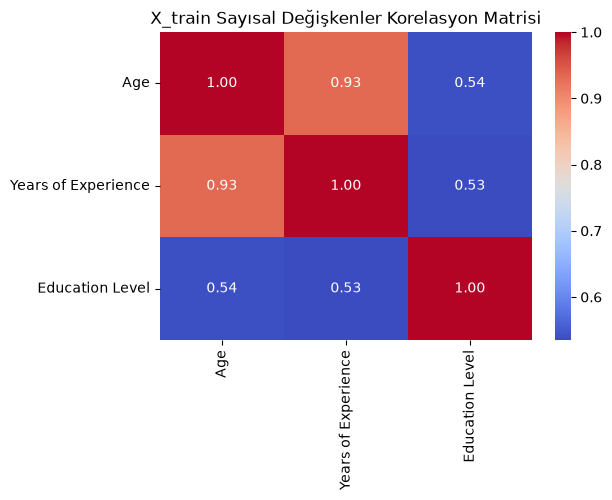

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

#Sadece sayısal sütunların korelasyon matrisini hesapla (Sadece Train üzerinden)
corr_matrix = X_train[["Age", "Years of Experience", "Education Level"]].corr()
print(corr_matrix)

#Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("X_train Sayısal Değişkenler Korelasyon Matrisi")
plt.show()

In [19]:
#age ve years of experience birbiriyle %94 korelasyon olduğu için age'i çıkarıyoruz
X_train = X_train.drop(columns=["Age"])
X_test = X_test.drop(columns=["Age"])

BLOK10: Kategorik Sütunları One-Hot Encoding ile Sayısallaştırma

In [20]:
from sklearn.preprocessing import OneHotEncoder

#kategorik sütunları seç
cat_cols = ["Gender", "Job Title"]

#encoder'ı tanımla (sparse_output=False ile doğrudan normal dizi döndürür)
#test setinde bir satırda daha önce train setinde hiç görülmemiş yeni bir kategori
#yer alırsa ne olur?: handle_unknown="ignore" parametresi sayesinde hiçbir hata oluşmaz
#OneHotEncoder sütun yapısını ve sayısını yalnızca X_train üzerinden fit ederken belirler
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

#kuralı SADECE train'den öğren ve dönüştür
#sütun şablonunu train belirler
X_train_cat = encoder.fit_transform(X_train[cat_cols])

# test'e sadece öğrenilen kuralı uygula (asla fit yok)
#test setine aynı şablon giydirilir
X_test_cat = encoder.transform(X_test[cat_cols])

In [21]:
import numpy as np

#sayısal sütunlar
num_cols = ["Education Level", "Years of Experience"]

#sayısal sütunlar ile one-hot matrisini yan yana yapıştır (np.hstack)
X_train_final = np.hstack([X_train[num_cols].values, X_train_cat])
X_test_final = np.hstack([X_test[num_cols].values, X_test_cat])

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
#ortalamayı sadece trainden öğren (fit_transform), teste sadece uygula (transform)
X_train_scaled = scaler.fit_transform(X_train_final)
#tüm girdi değişkenleri standart
#ortalama sıfır standart sapma 1 
#z score = girdi - ortalama / standart sapma
X_test_scaled = scaler.transform(X_test_final)

#y'nin yarışacağı başka sütun yok
#ölçeklersen model maaşı tl olarak değil, anlamsız z score olarak tahmin eder.

#girdileri adil bir şekilde eşitle, hedefi ne kadar para kazandığını okuyabilmek için bırak

BLOK12: Model Eğitimi ve Doğrulama

In [23]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#model tanımlama ve eğitme
model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)  #test verisi için tahmin

#Performans Metrikleri
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

#MSE: bir regresyon modelinin yaptığı tahminlerin gerçeğe ne kadar yakın olduğunu ölçer
print(f"MAE (ortalama mutlak hata) : {mae:.2f}")
print(f"RMSE (kök hata kareleri)   : {rmse:.2f}")
print(f"R kare Skoru (açıklama oranı) : {r2:.4f}")

MAE (ortalama mutlak hata) : 17761.82
RMSE (kök hata kareleri)   : 23453.22
R kare Skoru (açıklama oranı) : 0.8069
